# Credit Risk Assessment & Loan Default Prediction

## 01. Data Understanding

##### Objective

Understand the structure, size, variables, data types, and quality of the credit risk dataset before performing exploratory data analysis or building a machine learning model.

##### Approach
1. Load the Dataset
2. Inspect Dataset Structure
3. Check Data Quality
4. Understand the Target Variable
5. Summarize Numerical Features
6. Summarize Categorical Features
7. Summarize Initial Findings


#### Step 1: Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "C:/Users/user/Downloads/AI_Engineer/ML_Projects/Credit-Risk-ML/data/raw/credit_risk_dataset.csv"

df = pd.read_csv(file_path)

#### Step 2: Inspect Dataset Structure

In [2]:
display(df.head())

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

df.info()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


Dataset shape: (32581, 12)

Column names: ['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-nu

#### Step 3: Check Data Quality

In [3]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing_summary[missing_summary["Missing Count"] > 0])

print("Duplicate rows:", df.duplicated().sum())

,Missing Count,Missing Percentage
person_emp_length,895,2.75
loan_int_rate,3116,9.56


Duplicate rows: 165


#### Step 4: Understand the Target Variable

In [4]:
target_summary = pd.DataFrame({
    "Count": df["loan_status"].value_counts(),
    "Percentage": (
        df["loan_status"].value_counts(normalize=True) * 100
    ).round(2)
})

display(target_summary)

,Count,Percentage
loan_status,,
0,25473,78.18
1,7108,21.82


#### Step 5: Analyze Numerical Features

In [5]:
numerical_cols = df.select_dtypes(include="number").columns.drop("loan_status")

display(df[numerical_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.73,6.35,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.85,61983.12,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.79,4.14,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.37,6322.09,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.01,3.24,5.42,7.90,10.99,13.47,23.22
loan_percent_income,32581.0,0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.80,4.06,2.00,3.00,4.00,8.00,30.00


#### Step 6: Analyze Categorical Features

In [6]:
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

for col in categorical_cols:
    summary = pd.DataFrame({
        "Count": df[col].value_counts(dropna=False),
        "Percentage": (
            df[col].value_counts(normalize=True, dropna=False) * 100
        ).round(2)
    })

    print(f"\n{col}")
    display(summary)


person_home_ownership


,Count,Percentage
person_home_ownership,,
RENT,16446,50.48
MORTGAGE,13444,41.26
OWN,2584,7.93
OTHER,107,0.33



loan_intent


,Count,Percentage
loan_intent,,
EDUCATION,6453,19.81
MEDICAL,6071,18.63
VENTURE,5719,17.55
PERSONAL,5521,16.95
DEBTCONSOLIDATION,5212,16.00
HOMEIMPROVEMENT,3605,11.06



loan_grade


,Count,Percentage
loan_grade,,
A,10777,33.08
B,10451,32.08
C,6458,19.82
D,3626,11.13
E,964,2.96
F,241,0.74
G,64,0.20



cb_person_default_on_file


,Count,Percentage
cb_person_default_on_file,,
N,26836,82.37
Y,5745,17.63


#### Step 7: Summarize Initial Findings

| Finding                             | Evidence                                           | Planned action                                     |
| ----------------------------------- | -------------------------------------------------- | -------------------------------------------------- |
| Missing values                      | 895 employment lengths; 3,116 interest rates       | Investigate and choose suitable imputation methods |
| Duplicate records                   | 165 duplicates                                     | Confirm and handle in data cleaning                |
| Suspicious ages                     | 5 ages above 100                                   | Treat invalid values appropriately                 |
| Invalid employment lengths          | 2 values of 123 years                              | Treat invalid values appropriately                 |
| Highly skewed income may be present | Maximum income of 6,000,000                        | Investigate distribution during EDA                |
| Moderate class imbalance            | 78.18% non-default; 21.82% default                 | Use appropriate evaluation metrics                 |
| Potentially informative features    | Loan grade, previous default, loan-to-income ratio | Explore relationships with default in EDA          |


## 02. Exploratory Data Analysis (EDA)

#### Step 1: Understand the Purpose of EDA

##### Objective

Exploratory Data Analysis helps us understand the dataset,
identify patterns, compare features, and detect unusual values.

In this project, we want to understand which applicant
characteristics are associated with loan default.

Our target column is `loan_status`:

- 0 = No loan default
- 1 = Loan default

We will study important numerical and categorical features
before moving to data cleaning and preprocessing.

Important: Observed patterns do not prove that a feature
causes loan default.

#### Step 2: Understand the Target Distribution

##### Why are we doing this?

Before building a machine learning model, we should know how many applicants defaulted and how many did not.

,Applicants,Percentage
loan_status,,
0,25473,78.18
1,7108,21.82


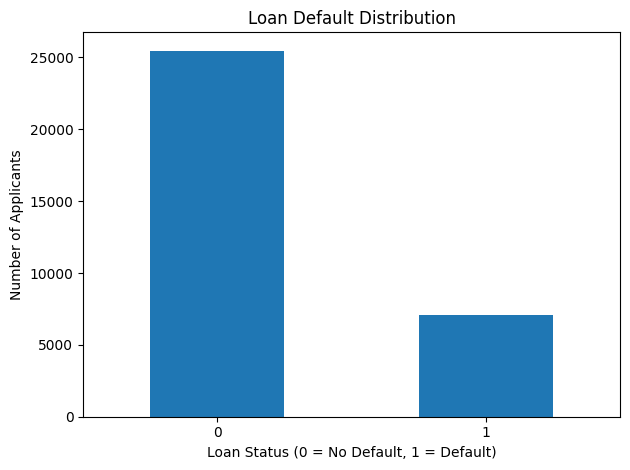

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the two target classes
target_counts = df["loan_status"].value_counts().sort_index()

# Display counts and percentages
target_summary = pd.DataFrame({
    "Applicants": target_counts,
    "Percentage": (target_counts / len(df) * 100).round(2)
})

display(target_summary)

# Visualize the target distribution
target_counts.plot(kind="bar")

plt.title("Loan Default Distribution")
plt.xlabel("Loan Status (0 = No Default, 1 = Default)")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Interpretation:

Your earlier analysis found approximately:

* 78.18% of applicants did not default.
* 21.82% of applicants defaulted.

This means the target classes are imbalanced. We'll remember this when evaluating our model later.

#### Step 3: Compare Numerical Features

##### Why are we doing this?

We want to see how numerical values differ between applicants who defaulted and those who did not.

We'll compare the median because unusually large values can affect the mean.

In [8]:
numeric_features = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

# Compare the median values for both target classes
median_comparison = df.groupby("loan_status")[numeric_features].median().T

median_comparison.columns = ["No Default", "Default"]

display(median_comparison.round(2))

,No Default,Default
person_age,26.00,26.00
person_income,60000.00,41498.00
person_emp_length,4.00,3.00
loan_amnt,8000.00,9600.00
loan_int_rate,10.59,13.49
loan_percent_income,0.13,0.24
cb_person_cred_hist_length,4.00,4.00


How to understand the output:

* Each row represents a numerical feature.
* No Default shows the median for applicants with loan_status = 0.
* Default shows the median for applicants with loan_status = 1.

For example, your earlier analysis found that the median loan amount was 8,000 for non-defaulting applicants and 9,600 for defaulting applicants.

Remember: A difference in medians is a pattern, not proof of causation.

#### Step 4: Visualize Important Numerical Features

##### Why are we doing this?

A boxplot helps us compare the distributions of numerical features between the two target classes.

Instead of creating many separate charts, we'll use one figure containing four useful comparisons.

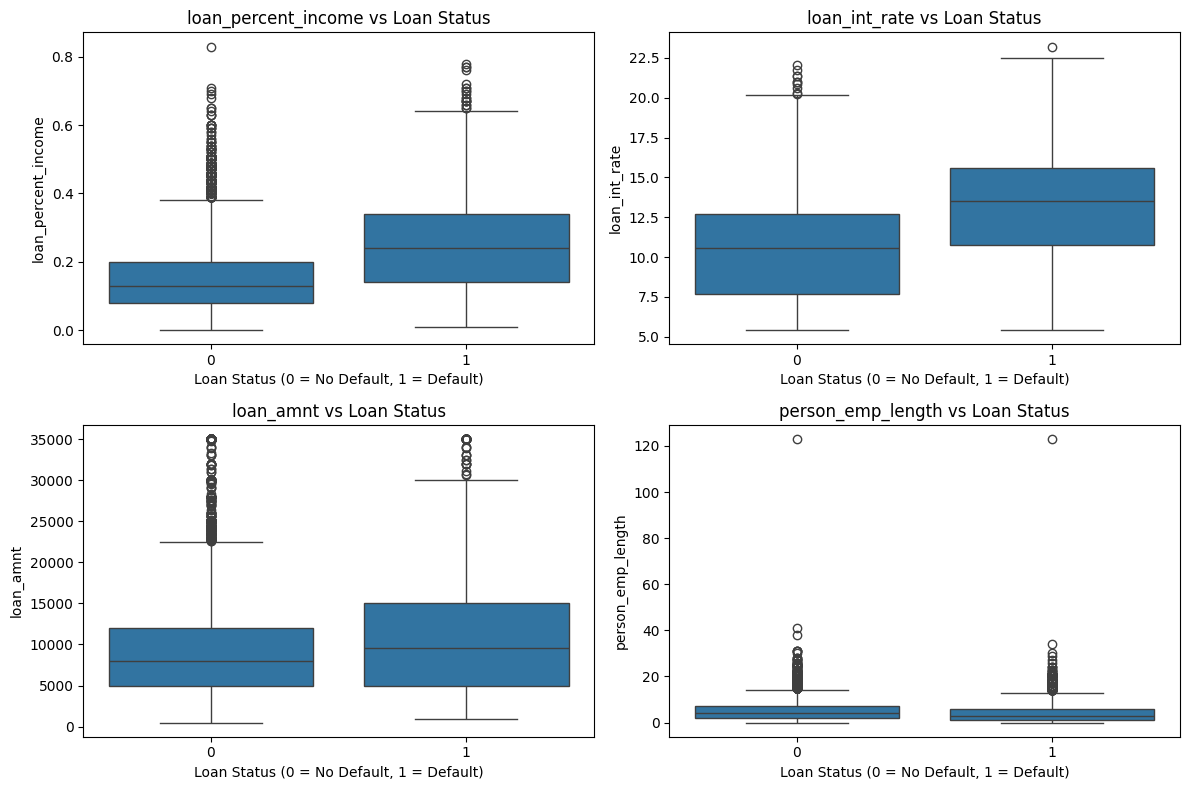

In [9]:
features_to_plot = [
    "loan_percent_income",
    "loan_int_rate",
    "loan_amnt",
    "person_emp_length"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features_to_plot):
    sns.boxplot(data=df, x="loan_status", y=feature, ax=ax)

    ax.set_title(f"{feature} vs Loan Status")
    ax.set_xlabel("Loan Status (0 = No Default, 1 = Default)")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

What should you observe?

Look for:

* Differences in the medians.
* Differences in the spread of the data.
* Overlap between the two groups.
* Unusually high or low values.

Your previous analysis found that the median loan-to-income ratio was higher among defaulting applicants: 0.24 compared with 0.13 among non-defaulting applicants. The interest-rate median was also higher for the default group.

#### Step 5: Compare Categorical Features

Why are we doing this?

Categorical features describe groups, such as home ownership and loan purpose.

We'll calculate three things for each category:

* Applicants: Number of applicants in that category.
* Defaults: Number of applicants who defaulted.
* Default rate: Percentage of applicants who defaulted.

We'll calculate all four features in one code cell rather than repeating similar code.

In [10]:
categorical_features = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file"
]

for feature in categorical_features:

    summary = df.groupby(feature)["loan_status"].agg(
        Applicants="count",
        Defaults="sum",
        Default_Rate="mean"
    )

    summary["Default_Rate"] = (
        summary["Default_Rate"] * 100
    ).round(2)

    summary = summary.sort_values(
        "Default_Rate",
        ascending=False
    )

    print(f"\nDefault Rate by {feature}")
    display(summary)


Default Rate by person_home_ownership


,Applicants,Defaults,Default_Rate
person_home_ownership,,,
RENT,16446,5192,31.57
OTHER,107,33,30.84
MORTGAGE,13444,1690,12.57
OWN,2584,193,7.47



Default Rate by loan_intent


,Applicants,Defaults,Default_Rate
loan_intent,,,
DEBTCONSOLIDATION,5212,1490,28.59
MEDICAL,6071,1621,26.70
HOMEIMPROVEMENT,3605,941,26.10
PERSONAL,5521,1098,19.89
EDUCATION,6453,1111,17.22
VENTURE,5719,847,14.81



Default Rate by loan_grade


,Applicants,Defaults,Default_Rate
loan_grade,,,
G,64,63,98.44
F,241,170,70.54
E,964,621,64.42
D,3626,2141,59.05
C,6458,1339,20.73
B,10451,1701,16.28
A,10777,1073,9.96



Default Rate by cb_person_default_on_file


,Applicants,Defaults,Default_Rate
cb_person_default_on_file,,,
Y,5745,2172,37.81
N,26836,4936,18.39


How to understand the results:

Pay attention to both the default rate and the number of applicants.

For example, a high default rate based on only a few applicants should be interpreted cautiously.

Your existing analysis has already identified the following patterns:

| Feature                  | Important observation                                                              |
| ------------------------ | ---------------------------------------------------------------------------------- |
| Home ownership           | RENT has a higher observed default rate than OWN.                                  |
| Loan intent              | DEBTCONSOLIDATION has the highest observed rate among the loan-purpose categories. |
| Loan grade               | Grade G has a high observed rate, but its group is small.                          |
| Previous default history | Applicants with a recorded previous default have a higher observed default rate.   |


#### Step 6: Visualize Categorical Features

##### Why are we doing this?

Tables give us exact values. Bar charts make it easier to compare categories visually.

We'll use one figure with four charts instead of creating separate charts for every feature.

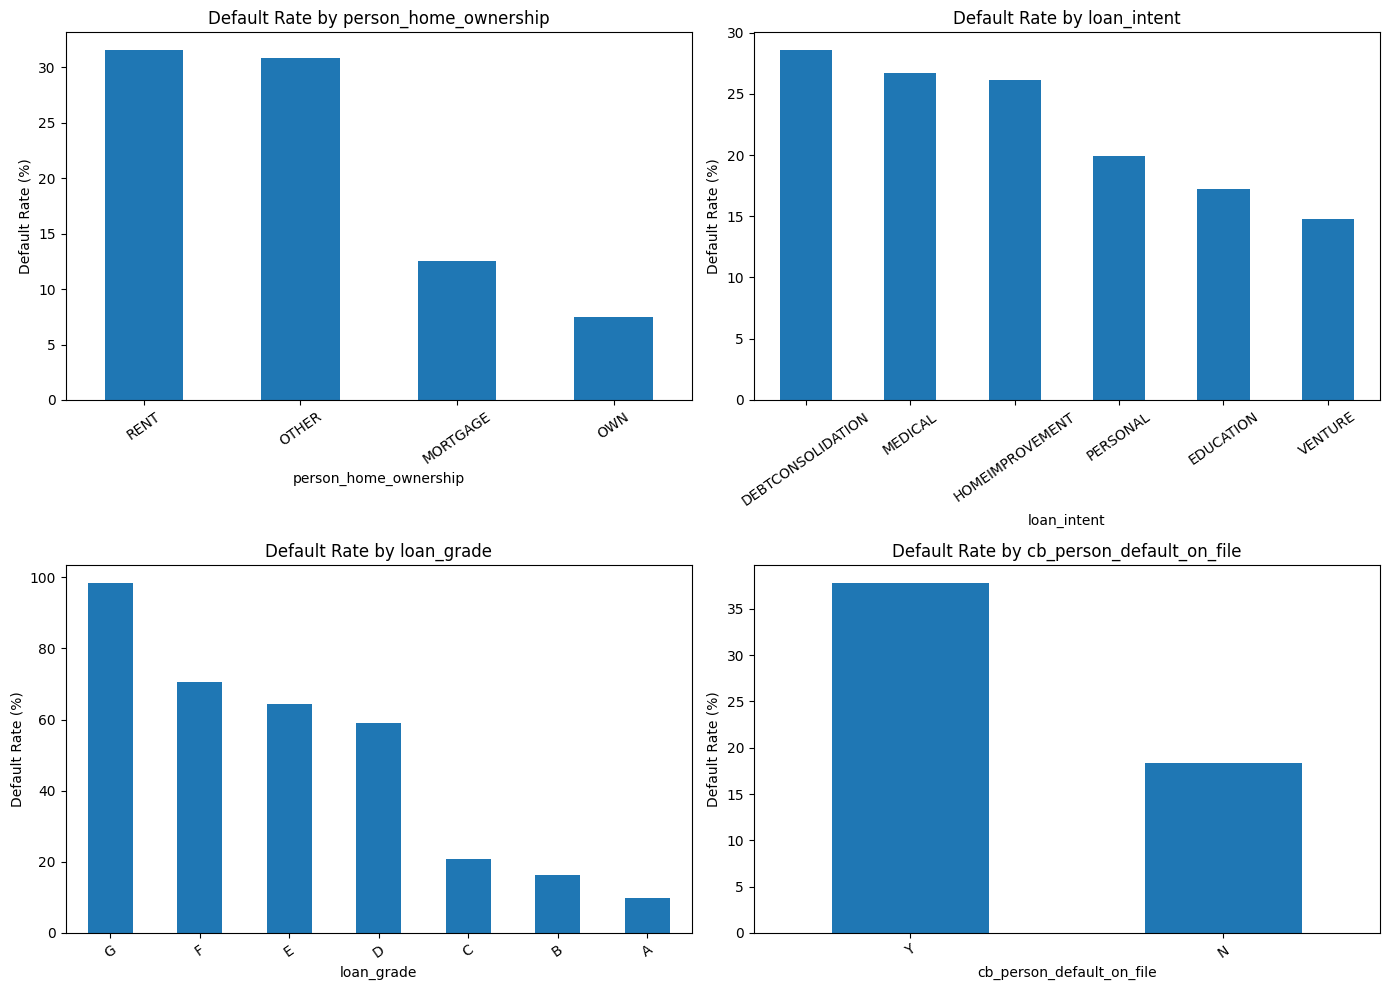

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature in zip(axes.flat, categorical_features):

    default_rates = (
        df.groupby(feature)["loan_status"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    default_rates.plot(kind="bar", ax=ax)

    ax.set_title(f"Default Rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Default Rate (%)")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

Interpretation:

* Taller bars represent higher observed default rates.
* Shorter bars represent lower observed default rates.
* Always check the category sizes in Step 5 before interpreting a high rate.

Important: These charts show associations. They do not establish that a category causes default.

#### Step 7: Investigate Unusual Applicant Ages

Your earlier analysis identified five records with ages above 100. Such values are unusual and should be investigated before deciding how to handle them.

In [12]:
# Display applicants whose recorded age exceeds 100
unusual_ages = df.loc[
    df["person_age"] > 100,
    ["person_age", "person_income", "loan_status"]
]

display(unusual_ages)

print("Number of unusual age records:", len(unusual_ages))

,person_age,person_income,loan_status
81,144,250000,0
183,144,200000,0
575,123,80004,0
747,123,78000,0
32297,144,6000000,0


Number of unusual age records: 5


Observation:

The dataset contains five records with ages above 100.

Decision for now: Flag these values for further investigation. Do not delete them or change their values during EDA.

We'll decide how to handle them during Phase 3.

#### Step 8: Investigate Unusual Employment Lengths

Your earlier analysis identified two records with an employment length above 50 years. These values are unusual compared with the applicant ages and should be investigated.

In [13]:
# Display applicants with employment length above 50 years
unusual_employment = df.loc[
    df["person_emp_length"] > 50,
    ["person_age", "person_emp_length", "loan_status"]
]

display(unusual_employment)

print(
    "Number of unusual employment records:",
    len(unusual_employment)
)

,person_age,person_emp_length,loan_status
0,22,123.0,1
210,21,123.0,0


Number of unusual employment records: 2


Observation:

Two records have an employment length of 123 years, which is implausible.

Decision for now: Flag these values. We will decide how to handle them during Phase 3 rather than modifying the data during EDA.

#### Step 9: Record the Main EDA Findings

##### Key Findings from EDA

1. Target distribution:
   The dataset contains more non-default cases than default cases.

2. Home ownership:
   RENT has a higher observed default rate than OWN.
   The OTHER category has relatively few applicants,
   so its rate requires caution.

3. Loan purpose:
   DEBTCONSOLIDATION has the highest observed default rate,
   while VENTURE has the lowest among the loan-purpose groups.

4. Loan grade:
   Default rates differ across loan grades.
   Grade G has a very high observed rate, but its sample is small.

5. Previous default history:
   Applicants with a recorded previous default have a higher
   observed default rate than applicants without one.

6. Numerical features:
   Loan-to-income ratio and interest rate have higher medians
   among applicants who defaulted in this dataset.

7. Unusual values:
   Some applicant ages and employment lengths are implausible
   and require further investigation.

Important:
These findings describe patterns in the dataset.
They do not prove that any feature causes loan default.

#### Step 10: Complete EDA and Prepare for the Next Phase

##### EDA Conclusion

Exploratory Data Analysis helped us understand the target
distribution, compare important features, identify patterns,
and flag unusual values.

We have also identified important data-quality concerns
that must be considered before building a machine learning model.

The dataset contains missing values and duplicate records,
which were identified during Data Understanding.

We have not deleted records, filled missing values,
or changed unusual values during this EDA phase.

### Next Phase

Phase 3: Data Cleaning and Preprocessing

In the next phase, we will decide how to handle:
- Missing values
- Duplicate records
- Implausible ages
- Implausible employment lengths
- Other necessary preprocessing requirements

1. Higher median → Which group typically has higher values?
2. Wider box → Which group has greater variation in its middle 50%?
3. Overlapping boxes → Do the groups share similar central values?
4. Outliers → Are there unusual observations worth investigating?
5. ML implication → Can this feature help distinguish the classes, and what are its limitations?

1. Mean and median: Are borrowers who defaulted younger or older on average? both default and non default are younger
2. Spread: How much do ages vary within each group? its nearly 6 year is varying within the person's age
3. Minimum and maximum: Are there unusually young or old borrowers who might require
further investigation? min 20 max 20 who is not unsuall young so no need of investigation


* Three borrowers have age of 144.
* Two borrowers have age of 123.
* All five belongs to non default grp

=> Ages of 123 and 144 -> implausible for loan applicant. likely data errors and warrant investigation.

1. obs1 -> most borrowers are relatively young ->
* 23 : 3889,
* 22,24,25 : high
* Interpretation: The dataset contains substantially more young borrowers than older borrowers.
2. obs2 -> no. of borrowers generally decreases at older ages. Interpretation: older borrowers are less represented in this dataset.
3. obs3 -> There are few extreme age values -> 5 : older than 100    

Percentage=Total records/Suspicious records×100

**Obs1**
* Non-default IQR = ₹12,000 − ₹5,000 = ₹7,000
* Default IQR = ₹15,000 − ₹5,000 = ₹10,000
  
**Obs2**
* Non-default median = ₹8,000
* Default median = ₹9,600

**Obs3**
* Non-default box: ₹5,000–₹12,000
* Default box: ₹5,000–₹15,000

##### Compare the boxes

| Group       |     Q1 | Median |     Q3 |  IQR |
| ----------- | -----: | -----: | -----: | ---: |
| Non-default |  7.68% | 10.59% | 12.69% | 5.01 |
| Default     | 10.74% | 13.49% | 15.58% | 4.84 |


cb_person_cred_hist_length represents the length of the borrower's credit history, measured in years.

* 2 means a credit history of approximately 2 years.
* 10 means a credit history of approximately 10 years.

* Observation 1 : Both medians has 4yrs
* Observation 2 : Both IQRs are 5yrs
* Observation 3 : Fully Overlap
  
The boxplots overlap completely, with identical medians and IQRs. The two groups have very similar distributions of credit history length.

cb_person_default_on_file -> It indicates whether the borrower has a recorded previous default.

* Y = Yes, a previous default is recorded.
* N = No previous default is recorded.

##### Calculate the difference in default rates
37.81% − 18.39% = 19.42 percentage points

##### Is the default rate twice as high?

Let's check the ratio:

$$ \frac{37.81}{18.39}\approx 2.06 $$

Yes! The observed default rate is approximately 2.06 times as high for the group with a recorded previous default.

Be precise when describing this:

* Absolute difference: 19.42 percentage points.
* Relative comparison: Approximately 2.06 times the default rate.

##### The loan_intent feature represents why a borrower wants the loan. The categories in this dataset are:

* EDUCATION
* MEDICAL
* VENTURE
* PERSONAL
* DEBTCONSOLIDATION
* HOMEIMPROVEMENT

##### Difference
28.59% − 14.81% = 13.78 percentage points

##### Let's also compare their rates:
$$ \frac{28.59}{14.81}\approx 1.93 $$

For debt consolidation:

$$ \text{Default rate}=\frac{1490}{5212}\times100 = 28.59% $$
	

##### The difference between the RENT and OWN default rates is:
31.57% − 7.47% = 24.10 percentage points

* Tallest bar: RENT, with a default rate of approximately 31.57%.
* Next tallest: OTHER, at approximately 30.84%.
* Lower bar: MORTGAGE, at approximately 12.57%.
* Shortest bar: OWN, at approximately 7.47%.

## 03. Data Cleaning & Preprocessing

##### Objective
Prepare a reliable dataset for machine learning by handling missing values, duplicate records, and implausible values while preserving useful information.

##### Our plan
- Create a working copy of the dataset.
- Check data quality.
- Handle duplicate records.
- Handle implausible ages.
- Handle implausible employment lengths.
- Impute missing numerical values.
- Check the cleaned dataset.
- Save the cleaned dataset.

We'll use 8 main steps rather than adding unnecessary code.

#### Step 1: Create a Working Copy
Why? We want to clean the data without changing the original dataset loaded into df.

In [14]:
# Create a separate copy for cleaning
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (32581, 12)
Working dataset shape: (32581, 12)


#### Step 2: Check Data Quality
Why? Let's confirm the missing values, duplicate records, and unusual values identified during the previous phases.

In [15]:
print("Missing values:")
display(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("\nAges above 100:", (df_clean["person_age"] > 100).sum())

print(
    "Employment lengths above 50:",
    (df_clean["person_emp_length"] > 50).sum()
)

Missing values:


person_emp_length     895
loan_int_rate        3116
dtype: int64


Duplicate rows: 165

Ages above 100: 5
Employment lengths above 50: 2


What does this code do?

* df.isnull().sum() counts missing values in each column.
* Missing Percentage calculates the percentage of missing values.
* The final line displays only columns that contain missing values.

From our earlier data understanding, we expect missing values in:

* person_emp_length
* loan_int_rate

#### Step 3: Remove Duplicate Records
Why? Exact duplicate rows may cause the same observation to be counted more than once.

In [16]:
df_clean = df_clean.drop_duplicates().copy()

print("Shape after removing duplicates:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Shape after removing duplicates: (32416, 12)
Remaining duplicate rows: 0


#### Step 4: Handle Implausible Ages

Your EDA identified five records with ages above 100. These values require careful treatment.

For this project, we'll flag ages above 100 as missing rather than automatically deleting the applicants. Later, we'll impute these values using the median age calculated from the remaining valid observations.

In [17]:
# Treat ages above 100 as invalid
df_clean.loc[df_clean["person_age"] > 100, "person_age"] = np.nan

print("Missing ages after cleaning:", df_clean["person_age"].isnull().sum())

Missing ages after cleaning: 5


Why this approach? It retains the applicants' other information instead of deleting their entire records.

Note: This is a practical cleaning assumption for the project, not proof that every person over 100 has an incorrect age.

#### Step 5: Handle Implausible Employment Lengths
Your EDA identified two employment lengths of 123 years. These values are implausible for this dataset.

We'll treat employment lengths above 50 years as missing and impute them in the next step.

In [18]:
# Treat implausible employment lengths as missing
df_clean.loc[
    df_clean["person_emp_length"] > 50,
    "person_emp_length"
] = np.nan

print(
    "Missing employment lengths:",
    df_clean["person_emp_length"].isnull().sum()
)

Missing employment lengths: 889


The missing employment-length count will now include the original missing values plus the two flagged values, unless some of those records were removed as duplicates.

#### Step 6: Handle Missing Numerical Values

We have three numerical columns that may need imputation:
- person_age
- person_emp_length
- loan_int_rate

We'll fill their missing values using each column's median.

Why median? Your dataset contains unusual and highly skewed values, particularly income. Median imputation is less affected by extreme values than mean imputation.

In [19]:
# Fill missing values using the median of each column
columns_to_impute = [
    "person_age",
    "person_emp_length",
    "loan_int_rate"
]

for col in columns_to_impute:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)

print("Missing values after imputation:")
display(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Missing values after imputation:


Series([], dtype: int64)

Important: We are using the full cleaned dataset at this stage to prepare the data. Before model training, we'll establish the train-test split and ensure that any learned preprocessing values are fitted using training data only. That prevents information leakage into the test set.

#### Step 7: Validate the Cleaned Dataset

In [20]:
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:", df_clean.isnull().sum().sum())

print("Remaining duplicate rows:", df_clean.duplicated().sum())

print("Ages above 100:", (df_clean["person_age"] > 100).sum())

print(
    "Employment lengths above 50:",
    (df_clean["person_emp_length"] > 50).sum()
)

print("\nFinal data types:")
display(df_clean.dtypes)

Cleaned dataset shape: (32416, 12)

Remaining missing values: 0
Remaining duplicate rows: 0
Ages above 100: 0
Employment lengths above 50: 0

Final data types:


person_age                    float64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

####  Step 8: Save the Cleaned Dataset
Let's save the cleaned dataset separately so the raw file remains unchanged.

In [22]:
cleaned_file_path = (
    "C:/Users/user/Downloads/AI_Engineer/ML_Projects/"
    "Credit-Risk-ML/data/raw/credit_risk_cleaned.csv"
)

df_clean.to_csv(cleaned_file_path, index=False)

print("Cleaned dataset saved successfully!")
print("File path:", cleaned_file_path)

Cleaned dataset saved successfully!
File path: C:/Users/user/Downloads/AI_Engineer/ML_Projects/Credit-Risk-ML/data/raw/credit_risk_cleaned.csv


## 04. Feature Engineering & Selection

#### Objective
Identify the features we should use to predict loan default and determine whether any useful new features are necessary.

#### Our plan:
| Step | Task                                        | What we'll do                                            |
| ---- | ------------------------------------------- | -------------------------------------------------------- |
| 1    | Load and inspect the cleaned dataset        | ✅ Completed                                              |
| 2    | Separate features and target                | Create `X` and `y`                                       |
| 3    | Review existing features                    | Understand their roles and usefulness                    |
| 4    | Check redundancy and potential leakage      | Examine `loan_grade` and `loan_percent_income` carefully |
| 5    | Decide on feature engineering and selection | Keep useful features; create new ones only if justified  |
| 6    | Finalize the feature set                    | Confirm the features we'll carry forward                 |


#### Step 1: Load and inspect the cleaned dataset
Your existing DataFrame is called df_clean.

In [28]:
# Check the cleaned dataset structure
print("Dataset shape:", df_clean.shape)

print("\nColumn names:")
print(df_clean.columns.tolist())

print("\nFirst five rows:")
display(df_clean.head())

Dataset shape: (32416, 12)

Column names:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

First five rows:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22.0,59000,RENT,4.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21.0,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25.0,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23.0,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24.0,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


#### Step 2: Separate Features (X) and Target (y)

In [29]:
# Separate features and target
X = df_clean.drop("loan_status", axis=1)
y = df_clean["loan_status"]

# Check the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (32416, 11)
Target shape: (32416,)


#### Step 3: Review Existing Features

In [30]:
# Review features and their data types
feature_summary = pd.DataFrame({
    "Data Type": X.dtypes,
    "Unique Values": X.nunique()
})

display(feature_summary)

,Data Type,Unique Values
person_age,float64,56
person_income,int64,4295
person_home_ownership,object,4
person_emp_length,float64,35
loan_intent,object,6
loan_grade,object,7
loan_amnt,int64,753
loan_int_rate,float64,348
loan_percent_income,float64,77
cb_person_default_on_file,object,2


#### Step 4: Check Redundancy and Potential Data Leakage

##### 4.1 — loan_amnt vs person_income vs loan_percent_income

In [35]:
# Check correlations between the three numerical features
X[["loan_amnt", "person_income", "loan_percent_income"]].corr()

,loan_amnt,person_income,loan_percent_income
loan_amnt,1.000000,0.265947,0.572824
person_income,0.265947,1.000000,-0.254472
loan_percent_income,0.572824,-0.254472,1.000000


| Feature pair                            | Correlation | Interpretation                 |
| --------------------------------------- | ----------: | ------------------------------ |
| `loan_amnt` ↔ `person_income`           |      +0.266 | Weak positive relationship     |
| `loan_amnt` ↔ `loan_percent_income`     |      +0.573 | Moderate positive relationship |
| `person_income` ↔ `loan_percent_income` |      −0.254 | Weak negative relationship     |


##### 4.2 — Investigate loan_grade

loan_grade may be predictive, but we must understand when it is assigned.

If the grade is assigned using information available before the loan-default prediction, it may be a legitimate feature. If it incorporates information unavailable at the prediction point or information derived from the target, it could cause leakage.

#### Step 6 — Finalize the Initial Feature Set

In [36]:
# Finalize features and target
X = df_clean.drop("loan_status", axis=1)
y = df_clean["loan_status"]

print("Number of features:", X.shape[1])
print("Target variable:", y.name)
print("Dataset shape:", X.shape)

Number of features: 11
Target variable: loan_status
Dataset shape: (32416, 11)


## 05. Train-Test Split
We'll use 80% for training and 20% for testing. stratify=y preserves approximately the same target-class proportions in both sets.

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (25932, 11)
Testing features: (6484, 11)
Training target: (25932,)
Testing target: (6484,)


- test_size=0.2: 20% reserved for final evaluation.
- random_state=42: makes the split reproducible.
- stratify=y: preserves the approximate default/non-default proportions.

In [39]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training target distribution:
loan_status
0    0.781
1    0.219
Name: proportion, dtype: float64

Testing target distribution:
loan_status
0    0.781
1    0.219
Name: proportion, dtype: float64


## 06. Model Building

- Prepare the leakage-safe training data.
- Build the preprocessing pipeline.
- Train Logistic Regression.
- Evaluate with precision, recall, F1-score, confusion matrix, and ROC-AUC.

#### Step 1: Prepare leakage-safe data

In [41]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Load the original dataset
df_model = pd.read_csv(
    r"C:\Users\user\Downloads\AI_Engineer\ML_Projects\Credit-Risk-ML\data\raw\credit_risk_dataset.csv"
)

# Remove duplicate records
df_model = df_model.drop_duplicates().copy()

# Mark implausible values as missing
df_model.loc[df_model["person_age"] > 100, "person_age"] = np.nan
df_model.loc[df_model["person_emp_length"] > 50, "person_emp_length"] = np.nan

# Separate features and target
X = df_model.drop("loan_status", axis=1)
y = df_model["loan_status"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the results
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nMissing values in training data:")
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

Training features: (25932, 11)
Testing features: (6484, 11)

Missing values in training data:
person_age              5
person_emp_length     729
loan_int_rate        2488
dtype: int64


#### Step 2: Build the preprocessing pipeline

- Numerical features: Median imputation + standardization.
- Categorical features: Most-frequent imputation + one-hot encoding.
- Model: Logistic Regression.

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

In [43]:
# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

In [46]:
#Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [47]:
# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [48]:
# Create the complete model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

In [49]:
print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)
print("\nPreprocessing pipeline created successfully.")

Numerical features: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

Categorical features: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

Preprocessing pipeline created successfully.


#### Step 3: Train the Logistic Regression model

In [50]:
# Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


## 07. Evaluation

#### Step 1: Evaluate the model

In [51]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [52]:
# Predict loan default classes
y_pred = model.predict(X_test)

In [53]:
# Predict default probabilities
y_prob = model.predict_proba(X_test)[:, 1]

In [56]:
# Calculate evaluation metrics
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.8694
Precision: 0.7737
Recall   : 0.5691
F1-Score : 0.6558
ROC-AUC  : 0.8679

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.95      0.92      5066
           1       0.77      0.57      0.66      1418

    accuracy                           0.87      6484
   macro avg       0.83      0.76      0.79      6484
weighted avg       0.86      0.87      0.86      6484

Confusion Matrix:
[[4830  236]
 [ 611  807]]


| Actual class   | Predicted: No default (0) | Predicted: Default (1) |
| -------------- | ------------------------: | ---------------------: |
| No default (0) |     4,830 — True Negative |   236 — False Positive |
| Default (1)    |      611 — False Negative |    807 — True Positive |


- Adjust the classification threshold: The default threshold is 0.5. Lowering it may help identify more defaulters, although it can increase false positives.
- Train a Random Forest classifier: Compare its performance with Logistic Regression to see whether it captures more complex patterns.

In [57]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get predicted probabilities from the trained model
y_prob = model.predict_proba(X_test)[:, 1]

# Compare different classification thresholds
for threshold in [0.5, 0.4, 0.3, 0.2]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(
        precision_score(y_test, y_pred_threshold, zero_division=0), 4
    ))
    print("Recall   :", round(
        recall_score(y_test, y_pred_threshold, zero_division=0), 4
    ))
    print("F1-Score :", round(
        f1_score(y_test, y_pred_threshold, zero_division=0), 4
    ))


Threshold: 0.5
Precision: 0.7737
Recall   : 0.5691
F1-Score : 0.6558

Threshold: 0.4
Precision: 0.7086
Recall   : 0.6432
F1-Score : 0.6743

Threshold: 0.3
Precision: 0.6319
Recall   : 0.7144
F1-Score : 0.6706

Threshold: 0.2
Precision: 0.5279
Recall   : 0.7877
F1-Score : 0.6321


For this baseline, 0.4 is the best threshold if we prioritize F1-score. If minimizing missed defaults is more important, 0.3 may be preferable, depending on the business costs.

#### Step 2 — Train a Random Forest model

In [58]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


class_weight="balanced" gives more weight to the minority default class during training. We'll check whether that improves default detection.

In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict classes and default probabilities
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluate performance
print("Random Forest Performance")
print("-" * 30)
print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1-Score :", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Performance
------------------------------
Accuracy : 0.9335
Precision: 0.9759
Recall   : 0.7137
F1-Score : 0.8244
ROC-AUC  : 0.931

Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      5066
           1       0.98      0.71      0.82      1418

    accuracy                           0.93      6484
   macro avg       0.95      0.85      0.89      6484
weighted avg       0.94      0.93      0.93      6484

Confusion Matrix:
[[5041   25]
 [ 406 1012]]


#### Compare both models

| Metric    | Logistic Regression | Random Forest | Better model  |
| --------- | ------------------: | ------------: | ------------- |
| Accuracy  |              86.94% |    **93.35%** | Random Forest |
| Precision |              77.37% |    **97.59%** | Random Forest |
| Recall    |              56.91% |    **71.37%** | Random Forest |
| F1-score  |              65.58% |    **82.44%** | Random Forest |
| ROC-AUC   |              86.79% |    **93.10%** | Random Forest |

##### Interpret the Random Forest results
[[5041   25]
 [ 406 1012]]

- 5,041 non-defaulters correctly identified.
- 25 non-defaulters incorrectly flagged as defaulters.
- 1,012 defaulters correctly identified.
- 406 defaulters missed.
 

#### Compare thresholds for Random Forest

In [60]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get default probabilities from Random Forest
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Compare classification thresholds
for threshold in [0.5, 0.4, 0.3, 0.2]:
    y_pred_threshold = (y_prob_rf >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(
        precision_score(y_test, y_pred_threshold, zero_division=0), 4
    ))
    print("Recall   :", round(
        recall_score(y_test, y_pred_threshold, zero_division=0), 4
    ))
    print("F1-Score :", round(
        f1_score(y_test, y_pred_threshold, zero_division=0), 4
    ))


Threshold: 0.5
Precision: 0.9741
Recall   : 0.7151
F1-Score : 0.8247

Threshold: 0.4
Precision: 0.9379
Recall   : 0.7348
F1-Score : 0.824

Threshold: 0.3
Precision: 0.8582
Recall   : 0.768
F1-Score : 0.8106

Threshold: 0.2
Precision: 0.6981
Recall   : 0.8152
F1-Score : 0.7521


For now, 0.5 is the best observed threshold for F1-score. However, we should not finalize it until we select the threshold using validation data rather than the test set.

#### Compare feature importance

In [61]:
# Extract the trained Random Forest classifier
rf_classifier = rf_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

# Calculate feature importance
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_classifier.feature_importances_
})

# Aggregate one-hot encoded categories into their original features
feature_importance["original_feature"] = (
    feature_importance["feature"]
    .str.replace(r"^(numerical|categorical)__", "", regex=True)
    .str.split("_")
    .str[0]
)

print(
    feature_importance
    .sort_values("importance", ascending=False)
    .head(15)
    .to_string(index=False)
)

                                    feature  importance original_feature
             numerical__loan_percent_income    0.202150             loan
                   numerical__person_income    0.157299           person
                   numerical__loan_int_rate    0.129270             loan
                       numerical__loan_amnt    0.079145             loan
               numerical__person_emp_length    0.054591           person
                  categorical__loan_grade_D    0.053012             loan
                      numerical__person_age    0.048981           person
    categorical__person_home_ownership_RENT    0.041594           person
      numerical__cb_person_cred_hist_length    0.038569               cb
                  categorical__loan_grade_A    0.021266             loan
categorical__person_home_ownership_MORTGAGE    0.020525           person
                  categorical__loan_grade_C    0.017180             loan
     categorical__person_home_ownership_OWN    0.01

#### Current Model Comparision
| Metric    | Logistic Regression | Random Forest |
| --------- | ------------------: | ------------: |
| Accuracy  |              86.94% |    **93.35%** |
| Precision |              77.37% |    **97.59%** |
| Recall    |              56.91% |    **71.37%** |
| F1-score  |              65.58% |    **82.44%** |
| ROC-AUC   |              86.79% |    **93.10%** |

Random Forest is currently the stronger model based on these results.

1. loan_percent_income — 20.22%
2. person_income — 15.73%
3. loan_int_rate — 12.93%
4. loan_amnt — 7.91%
5. person_emp_length — 5.46%

#### update the feature set

In [62]:
# Exclude loan_grade for the before-approval prediction scenario
X_train_final = X_train.drop(columns=["loan_grade"])
X_test_final = X_test.drop(columns=["loan_grade"])

# Identify feature types
numerical_features = X_train_final.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train_final.select_dtypes(
    include=["object"]
).columns.tolist()

print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))
print("Total features:", X_train_final.shape[1])
print("loan_grade excluded:", "loan_grade" not in X_train_final.columns)

Number of numerical features: 7
Number of categorical features: 3
Total features: 10
loan_grade excluded: True


#### Rebuild the preprocessing pipeline and train the final Random Forest

In [63]:
# Rebuild preprocessing without loan_grade

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_final = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Build the final Random Forest pipeline
rf_model_final = Pipeline([
    ("preprocessor", preprocessor_final),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model
rf_model_final.fit(X_train_final, y_train)

print("Final Random Forest model trained successfully.")
print("Features used:", X_train_final.shape[1])
print("Excluded feature: loan_grade")

Final Random Forest model trained successfully.
Features used: 10
Excluded feature: loan_grade


#### Create a validation set

In [64]:
from sklearn.model_selection import train_test_split

# Split existing training data into model-training and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_final,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train on the reduced training set
rf_model_final.fit(X_fit, y_fit)

# Predict default probabilities on validation data
y_val_prob = rf_model_final.predict_proba(X_val)[:, 1]

print("Model-training samples:", X_fit.shape[0])
print("Validation samples:", X_val.shape[0])
print("Validation default rate:", round(y_val.mean(), 4))

Model-training samples: 20745
Validation samples: 5187
Validation default rate: 0.2186


#### Select the decision threshold

In [65]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1-Score": f1_score(y_val, y_val_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results).round(4)
threshold_df

,Threshold,Precision,Recall,F1-Score
0,0.30,0.7709,0.7478,0.7592
1,0.35,0.8226,0.7196,0.7676
2,0.40,0.8682,0.7028,0.7768
3,0.45,0.8993,0.6852,0.7778
4,0.50,0.9262,0.6746,0.7806


In [66]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

# Predict default probabilities on the test set
y_test_prob = rf_model_final.predict_proba(X_test_final)[:, 1]

# Apply the selected threshold
selected_threshold = 0.40
y_test_pred = (y_test_prob >= selected_threshold).astype(int)

print("Selected Threshold:", selected_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Selected Threshold: 0.4
Accuracy: 0.9158
ROC-AUC: 0.9209

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.98      0.95      5066
           1       0.89      0.70      0.78      1418

    accuracy                           0.92      6484
   macro avg       0.91      0.84      0.87      6484
weighted avg       0.91      0.92      0.91      6484

Confusion Matrix:
[[4945  121]
 [ 425  993]]


## 08. Model Interpretation & Explainability.

#### Step 1: Identify Important Features

In [67]:
# Extract the fitted preprocessing and Random Forest components
fitted_preprocessor = rf_model_final.named_steps["preprocessor"]
fitted_rf = rf_model_final.named_steps["classifier"]

# Retrieve transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract feature importances
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_rf.feature_importances_
})

# Display the 10 most important transformed features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

importance_df.head(10).round(4)

,Feature,Importance
0,numerical__loan_int_rate,0.2054
1,numerical__loan_percent_income,0.2017
2,numerical__person_income,0.1642
3,numerical__loan_amnt,0.0908
4,numerical__person_emp_length,0.0581
5,numerical__person_age,0.0558
6,numerical__cb_person_cred_hist_length,0.0447
7,categorical__person_home_ownership_RENT,0.0383
8,categorical__person_home_ownership_MORTGAGE,0.0237
9,categorical__cb_person_default_on_file_N,0.0157


#### Step 2: Understand Feature Direction

In [68]:
from sklearn.inspection import permutation_importance

# Measure feature importance on the validation set
perm_result = permutation_importance(
    rf_model_final,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
}).sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

permutation_df.round(4)

,Feature,Importance_Mean,Importance_Std
0,loan_int_rate,0.0874,0.0019
1,loan_percent_income,0.0850,0.0034
2,person_home_ownership,0.0771,0.0017
3,person_income,0.0523,0.0028
4,loan_intent,0.0398,0.0017
5,cb_person_default_on_file,0.0137,0.0009
6,loan_amnt,0.0081,0.0024
7,person_emp_length,0.0067,0.0015
8,person_age,0.0036,0.0026
9,cb_person_cred_hist_length,-0.0008,0.0007


## 09. Model Saving & Deployment Preparation

In [69]:
from pathlib import Path
import joblib

# Create the models directory
project_path = Path(
    r"C:\Users\user\Downloads\AI_Engineer\ML_Projects\Credit-Risk-ML"
)

models_path = project_path / "models"
models_path.mkdir(parents=True, exist_ok=True)

# Save the complete trained pipeline
model_path = models_path / "credit_risk_random_forest.joblib"

joblib.dump(rf_model_final, model_path)

# Save the selected prediction threshold separately
threshold_path = models_path / "decision_threshold.txt"
threshold_path.write_text("0.40", encoding="utf-8")

print("Model saved:", model_path)
print("Decision threshold saved:", threshold_path)

Model saved: C:\Users\user\Downloads\AI_Engineer\ML_Projects\Credit-Risk-ML\models\credit_risk_random_forest.joblib
Decision threshold saved: C:\Users\user\Downloads\AI_Engineer\ML_Projects\Credit-Risk-ML\models\decision_threshold.txt


In [70]:
import joblib
import numpy as np

# Load the saved model
loaded_model = joblib.load(model_path)

# Load the saved threshold
saved_threshold = float(
    threshold_path.read_text(encoding="utf-8").strip()
)

# Predict default probabilities for a few test samples
sample_data = X_test_final.head(5)
sample_probabilities = loaded_model.predict_proba(sample_data)[:, 1]

# Convert probabilities into predictions
sample_predictions = (
    sample_probabilities >= saved_threshold
).astype(int)

print("Model loaded successfully:", loaded_model is not None)
print("Saved threshold:", saved_threshold)
print("\nSample predictions:")

print(pd.DataFrame({
    "Default_Probability": np.round(sample_probabilities, 4),
    "Predicted_Loan_Status": sample_predictions
}, index=sample_data.index))

Model loaded successfully: True
Saved threshold: 0.4

Sample predictions:
       Default_Probability  Predicted_Loan_Status
21278                0.140                      0
26976                0.210                      0
26455                0.005                      0
24178                0.015                      0
25069                1.000                      1
